# 12 · פרויקט מסכם ופרשנות

<div dir="rtl">

## המטרה

חזי median_house_value בדולרים. החזירי Pipeline לא מאומן עם השלמה בחציון ו־RandomForestRegressor: 100 עצים, min_samples_leaf=2, random_state=42, n_jobs=1. חלוקה 25% עם seed=42; RMSE צריך להיות נמוך מ־85% מ־DummyRegressor. בצעי EDA, CV על train ו־permutation importance על validation, ורק בסוף הערכה אחת על test. SHAP הוא הרחבה אופציונלית (התקנה נפרדת). כתבי 300–500 מילים: שאלה, אוכלוסייה, איכות, החלטות, מדדים מול בסיס, מגבלות גאוגרפיות/זמן והמלצה. חזרי על החלוקה לפי אזור ודוני באופטימיות של פיצול אקראי. זהו רף אוטומטי מינימלי; המסקנה והפרשנות ייבדקו עם המורה.

זמן מומלץ: 150 דקות. קראי את `data/README.md` לפני העבודה.

## הכנה

הריצי את התא הבא. הנתונים מקומיים; אין צורך להוריד אותם שוב.

</div>

**פתרון ייחוס למורה — פתיחה רק בבקשה מפורשת.**

In [1]:
from pathlib import Path
import sys
import importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.common import load
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (8, 5)
frame = load("california")
frame.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-119.01,36.06,25.0,1505.0,NaN,1392.0,359.0,1.6812,47700.0
1,-119.46,35.14,30.0,2943.0,NaN,1565.0,584.0,2.5313,45800.0
2,-122.44,37.80,52.0,3830.0,NaN,1310.0,963.0,3.4801,500001.0
3,-118.72,34.28,17.0,3051.0,NaN,1705.0,495.0,5.7376,218600.0
4,-121.93,36.62,34.0,2351.0,NaN,1063.0,428.0,3.7250,278000.0


## העבודה שלך

השלימי את `make_regressor()` בקובץ `src/ex12.py`.

כתבי לפני הקוד: מה את מצפה למצוא, ואילו נתונים חסרים כדי לפרש את התוצאה?

התא הבא בטוח להרצה: הקריאה לפונקציה נשארת בהערה עד שתשלימי אותה.

In [2]:
import solutions.ex12 as student
answer = student.make_regressor()
answer

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('impute', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for 

<details><summary>רמז ראשון — לחצי רק אחרי ניסיון עצמאי</summary>

חשיבות פרמוטציה אינה סיבתיות ומשתנים מתואמים יכולים להסתיר חשיבות.

</details>

<details><summary>רמז שני — איך להתקדם?</summary>

פתחי את הבדיקה `tests/test_ex12.py`, זהי ציפייה אחת, ונסי לממש אותה על טבלה קטנה. בקשי מהמורה שאלה מכוונת לפני קוד.

</details>

## חקירה והצגה

הוסיפי כאן את הגרפים וההשוואות שנדרשו במטרה. לכל גרף: כותרת, יחידות, מכנה ומשפט פרשנות. קוד ותוויות גרפים באנגלית; הדיון בעברית.

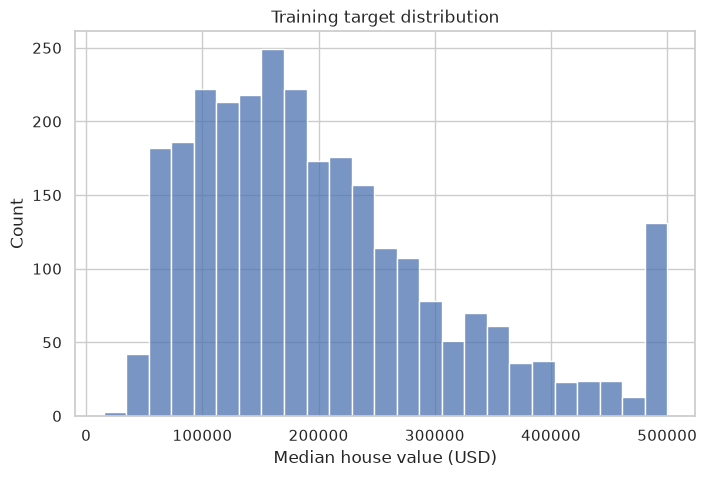

CV RMSE: 59890.0997026698 SD: 326.930481233227


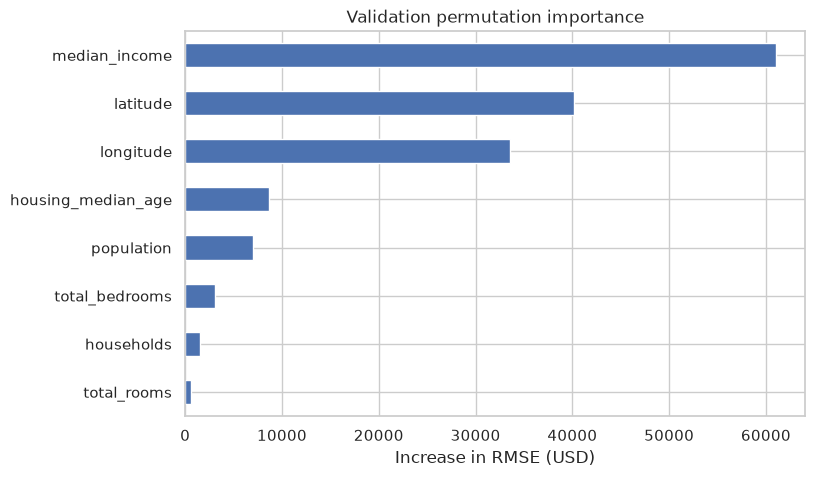

Final test RMSE: 57193.10171664106
Dummy RMSE: 117816.91934397107


Geographic validation RMSE: 156862.2214204043


In [3]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error
from sklearn.dummy import DummyRegressor
X = frame.drop(columns="median_house_value"); y = frame.median_house_value
X_dev,X_test,y_dev,y_test = train_test_split(X,y,test_size=.25,random_state=42)
X_train,X_val,y_train,y_val = train_test_split(X_dev,y_dev,test_size=.25,random_state=42)
sns.histplot(y_train); plt.xlabel("Median house value (USD)"); plt.title("Training target distribution"); plt.show()
scores = cross_val_score(answer,X_train,y_train,cv=3,scoring="neg_root_mean_squared_error")
print("CV RMSE:",-scores.mean(),"SD:",scores.std())
answer.fit(X_train,y_train)
importance = permutation_importance(answer,X_val,y_val,n_repeats=5,random_state=42,scoring="neg_root_mean_squared_error",n_jobs=1)
ranked = pd.Series(importance.importances_mean,index=X.columns).sort_values()
ranked.plot.barh(); plt.xlabel("Increase in RMSE (USD)"); plt.title("Validation permutation importance"); plt.show()
answer.fit(X_dev,y_dev)
baseline = DummyRegressor().fit(X_dev,y_dev)
print("Final test RMSE:",mean_squared_error(y_test,answer.predict(X_test))**.5)
print("Dummy RMSE:",mean_squared_error(y_test,baseline.predict(X_test))**.5)
# Geographic stress test uses development data only.
region = X_dev.longitude < X_dev.longitude.median()
answer.fit(X_dev.loc[region],y_dev.loc[region])
print("Geographic validation RMSE:",mean_squared_error(y_dev.loc[~region],answer.predict(X_dev.loc[~region]))**.5)


## בדיקה ומשוב

בטרמינל משורש המאגר:

```bash
make check EX=12
```

כישלון עם `NotImplementedError` צפוי לפני השלמת הפונקציה. הצלחת הבדיקות מאמתת רק את חוזה הקוד; היא אינה ציון לאיכות הניתוח.

מחוון מתוך 10: קוד ובדיקות 4; גרפים וחקירה 2; מניעת הטיות/דליפה 2; פרשנות ומגבלות 2. יעד מעבר: 8 וכל בדיקות הקוד עוברות.

## דיון למורה

יש לבסס מסקנה על הפלט שהורץ. דרשי הבחנה בין קשר וסיבתיות, תיאור אוכלוסיית המדגם והערכת הכללה. אין מסקנה קלינית הנובעת מציון גבוה בלבד. בתרגיל 11 הדילול משנה את שכיחות האימון ולכן עלול לפגוע בהעברת הכיול לאוכלוסיית המבחן. בתרגיל 12 השווי ל־dummy ובחני עד כמה החלוקה הגאוגרפית משנה את ההמלצה. אין תשובה מילולית יחידה: השתמשי במחוון שבמחברת להערכת ההנמקה.

## מסקנה לדוגמה — אינה מסקנה על שוק הדיור כיום

שאלת הניתוח היא האם מאפייני קבוצות בלוקים בקליפורניה מאפשרים לחזות את מחיר הבית החציוני טוב יותר מניחוש קבוע. יחידת התצפית אינה בית או משק בית, אלא אזור קטן במפקד של שנת 1990. לכן התוצאה מתארת יכולת חיזוי בתוך מאגר היסטורי ואינה מספקת הערכת שווי לנכס מסוים כיום. השתמשנו בדגימה קבועה של 5,000 שורות, ושמרנו רבע מהן למבחן סופי. פיצול נוסף בתוך נתוני הפיתוח שימש לבחינת חשיבות המשתנים.

בשלב ההכנה נשמרו החסרים במספר חדרי השינה והושלמו בחציון בתוך Pipeline. כך חישוב החציון בכל קפל התבסס על נתוני האימון בלבד. בחרנו יער אקראי עם הגבלה על גודל העלה כדי לצמצם התאמת יתר. לא כיווננו את מספר העצים לפי תוצאת המבחן. ב־cross-validation על האימון התקבל RMSE ממוצע של כ־59,890 דולר, עם סטיית תקן של כ־327 דולר בין שלושה קפלים. פיזור זה מתאר הבדלים בין החלוקות, ואינו רווח סמך ליכולת ההכללה.

במבחן האקראי הסופי התקבלה שגיאה של כ־57,193 דולר, לעומת כ־117,817 דולר במודל המנבא תמיד את ממוצע האימון. זהו שיפור ניכר לעומת הבסיס שנבחר, אך RMSE מעניק משקל גדול לשגיאות קיצוניות ולכן ראוי להוסיף MAE וניתוח שאריות לפי אזור ורמת מחיר. בנתונים קיימת גם תקרת מחיר, העלולה להקשות על פירוש ביצועים באזורי הדיור היקרים ביותר.

חשיבות הפרמוטציה בנתוני האימות הצביעה על הכנסה חציונית ועל קווי הרוחב והאורך כמשתנים מועילים לחיזוי. אין בכך הוכחה שהכנסה גורמת לשינוי במחיר, ואין להסיק שמאפיין בעל חשיבות נמוכה אינו רלוונטי. מאפיינים מתואמים יכולים לחלוק מידע, והחשיבות תלויה במודל ובמדגם. בנוסף, שימוש בסיכום אזורי אינו מאפשר להסיק ישירות על אדם או על בית בתוך אותו אזור.

במבחן העברה גאוגרפית נפרד, שנערך רק בתוך נתוני הפיתוח, השגיאה עלתה לכ־156,862 דולר. החלוקה הזו שינתה גם את גודל האימון ואת התפלגות המאפיינים, ולכן ההשוואה אינה ניסוי מבוקר המבודד את השפעת הגאוגרפיה בלבד. עם זאת, הפער מצביע על סיכון ממשי בהסתמכות על פיצול אקראי לצורך פריסה באזור חדש. ההמלצה היא להמשיך לאימות מרחבי מתוכנן, לבחון נתונים מתקופה עדכנית ולדווח שגיאות לפי תתי־אזורים לפני שימוש תפעולי. המודל מתאים בשלב זה להדגמת תהליך מחקרי ולהשוואת שיטות, ולא לקבלת החלטת רכישה או מדיניות ללא בדיקות נוספות.
